# Project 2 — Portfolio Optimization & the Efficient Frontier

**Group members:**
- [First Last]
- [First Last]
- [First Last]

*Course: Python for Finance (Beginner)*

---

## What this notebook does
We build a portfolio of **10 publicly traded stocks** and use **Modern Portfolio Theory (MPT)** to find the mix of weights that gives the **highest Sharpe ratio** (best return per unit of risk). We then plot the **efficient frontier** and mark our optimal ("tangency") portfolio on it.

The steps:
1. Download 5 years of daily prices with `yfinance`.
2. Turn prices into daily returns, then annualize them.
3. **Stock-selection analysis:** per-stock return/volatility, a cumulative-return plot, and a correlation heatmap — to justify our picks.
4. Build thousands of random portfolios, compute each one's return, volatility, and Sharpe ratio.
5. Pick the max-Sharpe portfolio, report its weights, and plot the efficient frontier.

## Assumptions (so a grader can follow our logic)

| Item | Choice |
|---|---|
| **Data source** | Daily adjusted close from `yfinance` (with `auto_adjust=True`, the `Close` column is already split/dividend-adjusted) |
| **Data window** | 2020-01-01 to 2025-01-01 (~5 years of trading days) |
| **Return type** | Simple daily returns via `pct_change()` |
| **Annualization** | annual return = mean daily return × **252**; annual volatility = daily std × **√252** |
| **Risk-free rate `Rf`** | Most recent 3-month T-bill yield (ticker `^IRX`); falls back to **3%** if the download fails |
| **Constraints** | **Long-only**: every weight ≥ 0, and all weights sum to 1 (no short-selling, no leverage) |
| **Optimization method** | Monte Carlo — generate many random long-only portfolios and keep the one with the highest Sharpe ratio |

We chose **long-only** because it is the realistic default for most investors (you can't easily short stocks in a normal brokerage account) and it keeps the math simple.

## Step 0 — Setup

If `yfinance` isn't installed yet, run the install line once (remove the `#`). You may need to restart the kernel afterward.

In [2]:
# Run this ONCE if yfinance is not installed, then restart the kernel:
#!pip install yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# Make plots show up inline and look a bit nicer
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True

## Step 1 — Choose our 10 stocks and download the data

We deliberately picked stocks from **different sectors** so the portfolio isn't all riding on one industry. That mix is what makes diversification possible:

| Ticker | Company | Sector |
|---|---|---|
| AAPL | Apple | Technology |
| MSFT | Microsoft | Technology |
| NVDA | Nvidia | Semiconductors |
| JPM | JPMorgan Chase | Financials |
| JNJ | Johnson & Johnson | Healthcare |
| XOM | ExxonMobil | Energy |
| PG | Procter & Gamble | Consumer staples |
| KO | Coca-Cola | Consumer staples |
| WMT | Walmart | Retail |
| NEE | NextEra Energy | Utilities |

Our hypothesis going in: the three tech names should be fairly correlated, while staples (PG, KO), the utility (NEE), and energy (XOM) should move more independently — giving us diversification benefit.

In [3]:
# Our 10 tickers
tickers = ['AAPL', 'MSFT', 'NVDA', 'JPM', 'JNJ', 'XOM', 'PG', 'KO', 'WMT', 'NEE']

# Data window
start_date = '2020-01-01'
end_date   = '2025-01-01'

# Download. auto_adjust=True means the 'Close' column is ALREADY adjusted
# for dividends and stock splits (this replaces the old 'Adj Close').
raw = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)

# When downloading several tickers, 'Close' is a table with one column per ticker
prices = raw['Close']

# Keep the columns in the same order as our tickers list
prices = prices[tickers]

# Drop any rows with missing values, just to be safe
prices = prices.dropna()

print("Price table shape (rows = days, cols = stocks):", prices.shape)
prices.tail()

[*********************100%***********************]  10 of 10 completed

Price table shape (rows = days, cols = stocks): (1258, 10)


Ticker,AAPL,MSFT,NVDA,JPM,JNJ,XOM,PG,KO,WMT,NEE
Date,,,,,,,,,,
2024-12-24,256.560852,434.179321,140.174072,233.964600,139.964752,101.266327,162.209656,60.233421,91.438751,70.225639
2024-12-26,257.375580,432.973663,139.884171,234.766022,139.705627,101.351982,163.381058,59.974621,91.547295,69.705528
2024-12-27,253.967377,425.482513,136.965118,232.863876,139.197021,101.342476,162.776169,59.859600,90.432419,69.455101
2024-12-30,250.598892,419.849365,137.444946,231.077576,137.556015,100.657204,160.433365,59.457020,89.357018,69.117989
2024-12-31,248.830200,416.558411,134.246017,231.454147,138.784363,102.379860,160.971054,59.677479,89.139961,69.050552


## Step 2 — Convert prices to daily returns

A **daily return** is the percent change in price from one day to the next. `pct_change()` does exactly this. The first row becomes `NaN` (there's no prior day to compare to), so we drop it.

In [4]:
# Daily simple returns
returns = prices.pct_change().dropna()

print("Returns table shape:", returns.shape)
returns.head()

Returns table shape: (1257, 10)


Ticker,AAPL,MSFT,NVDA,JPM,JNJ,XOM,PG,KO,WMT,NEE
Date,,,,,,,,,,
2020-01-03,-0.009722,-0.012452,-0.016006,-0.013196,-0.011578,-0.008039,-0.006726,-0.005456,-0.008828,0.007124
2020-01-06,0.007968,0.002585,0.004194,-0.000795,-0.001248,0.007678,0.001387,-0.000366,-0.002036,0.004993
2020-01-07,-0.004703,-0.009118,0.012107,-0.017001,0.006107,-0.008184,-0.006191,-0.007683,-0.009265,-0.000870
2020-01-08,0.016086,0.015928,0.001876,0.007801,-0.000138,-0.015080,0.004263,0.001844,-0.003432,-0.000456
2020-01-09,0.021241,0.012493,0.010983,0.003652,0.002966,0.007656,0.010938,0.018215,0.010330,0.007836


## Step 3 — Stock-selection analysis (required)

### 3a. Each stock's past performance
We annualize using the factors from the assumptions: mean daily return × 252 for return, and daily std × √252 for volatility. This tells us, per stock, roughly how much it returned per year and how bumpy the ride was.

In [5]:
# Annualize per stock
ann_return = returns.mean() * 252            # average daily return, scaled to a year
ann_vol    = returns.std()  * np.sqrt(252)   # daily volatility, scaled to a year

# Put them side by side in a small table
performance = pd.DataFrame({
    'Annualized Return': ann_return,
    'Annualized Volatility': ann_vol
})
performance['Return / Risk'] = performance['Annualized Return'] / performance['Annualized Volatility']

# Show as percentages, sorted by return
performance_pct = performance.copy()
performance_pct['Annualized Return'] = (performance_pct['Annualized Return'] * 100).round(1)
performance_pct['Annualized Volatility'] = (performance_pct['Annualized Volatility'] * 100).round(1)
performance_pct['Return / Risk'] = performance_pct['Return / Risk'].round(2)
performance_pct.sort_values('Annualized Return', ascending=False)

,Annualized Return,Annualized Volatility,Return / Risk
Ticker,,,
NVDA,76.9,53.9,1.43
AAPL,29.8,31.7,0.94
MSFT,24.9,30.5,0.82
WMT,20.6,22.6,0.91
XOM,19.1,34.4,0.56
JPM,18.8,32.5,0.58
PG,10.8,20.9,0.52
NEE,10.7,30.4,0.35
KO,7.8,20.8,0.37


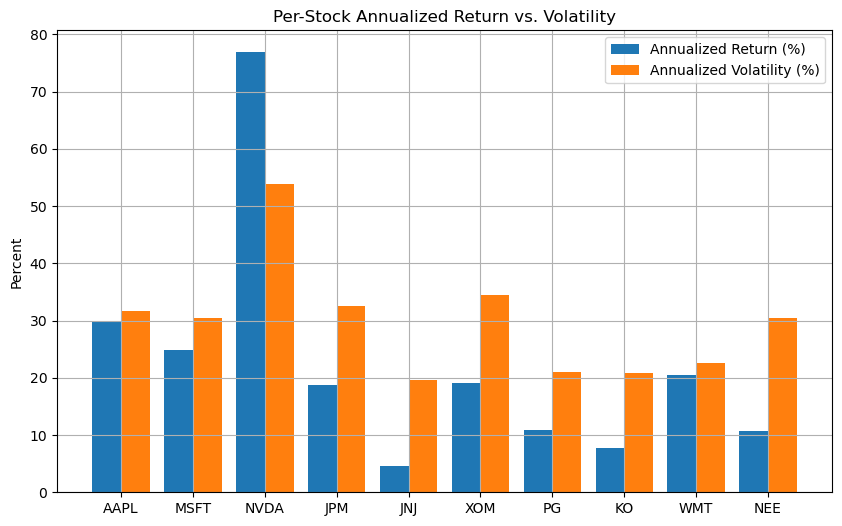

In [6]:
# Bar chart of annualized return vs volatility for each stock
x = np.arange(len(tickers))
width = 0.4

fig, ax = plt.subplots()
ax.bar(x - width/2, ann_return.values * 100, width, label='Annualized Return (%)')
ax.bar(x + width/2, ann_vol.values * 100, width, label='Annualized Volatility (%)')
ax.set_xticks(x)
ax.set_xticklabels(tickers)
ax.set_ylabel('Percent')
ax.set_title('Per-Stock Annualized Return vs. Volatility')
ax.legend()
plt.show()

### 3b. Cumulative return — "growth of \$1"
This shows what \$1 invested in each stock would have grown to over the window. It's an easy way to see winners, losers, and how differently the stocks behaved.

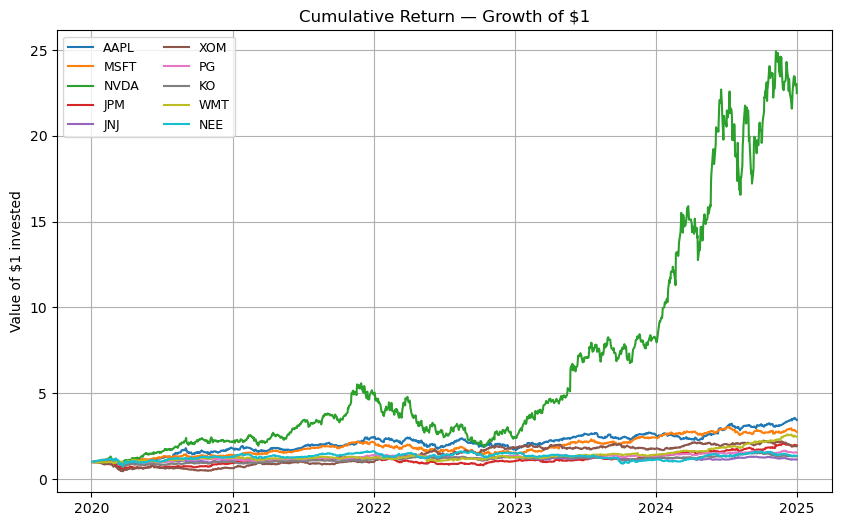

In [6]:
# Growth of $1 = running product of (1 + daily return)
cumulative = (1 + returns).cumprod()

fig, ax = plt.subplots()
for t in tickers:
    ax.plot(cumulative.index, cumulative[t], label=t)
ax.set_title('Cumulative Return — Growth of $1')
ax.set_ylabel('Value of $1 invested')
ax.legend(ncol=2, fontsize=9)
plt.show()

### 3c. Correlation matrix (heatmap)
Correlation measures how much two stocks move **together**, from -1 (opposite) to +1 (identical). For diversification we *want* some low or negative correlations — combining stocks that don't move in lockstep is what reduces overall portfolio risk.

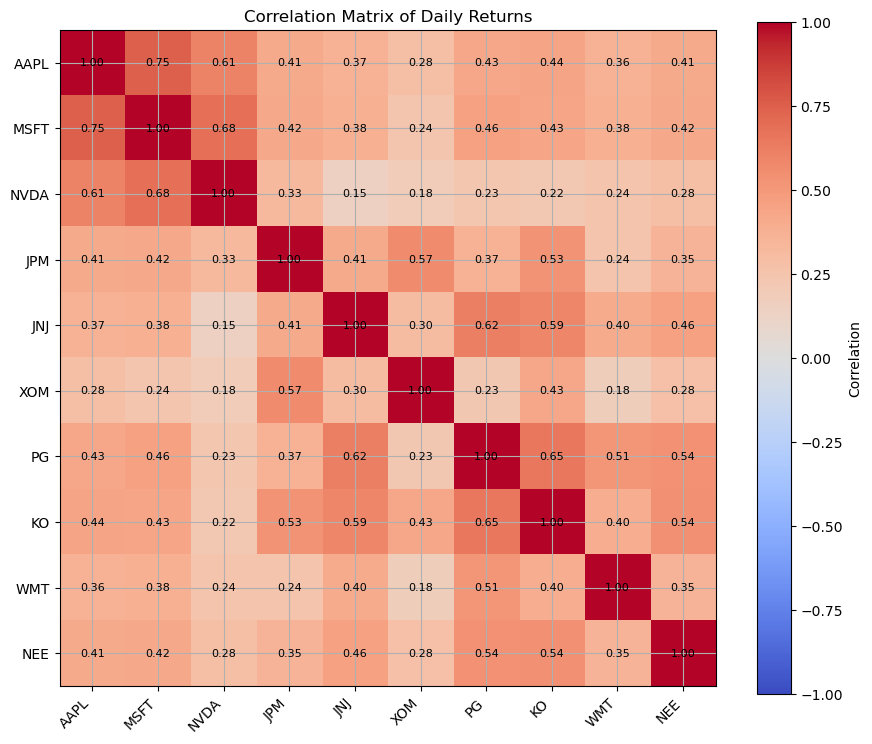

In [7]:
# Correlation of daily returns
corr = returns.corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

# Axis labels
ax.set_xticks(np.arange(len(tickers)))
ax.set_yticks(np.arange(len(tickers)))
ax.set_xticklabels(tickers, rotation=45, ha='right')
ax.set_yticklabels(tickers)

# Write the correlation number inside each cell
for i in range(len(tickers)):
    for j in range(len(tickers)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center',
                color='black', fontsize=8)

ax.set_title('Correlation Matrix of Daily Returns')
fig.colorbar(im, label='Correlation')
plt.tight_layout()
plt.show()

**What the correlation heatmap tells us (comment for the grader / presentation):**

- The three tech names (**AAPL, MSFT, NVDA**) are the most correlated block — they tend to rise and fall together, so holding all three doesn't diversify much *within* tech.
- **Consumer staples (PG, KO)** and the **utility (NEE)** show noticeably lower correlation with tech. These are the "steady" names that cushion the portfolio when tech sells off.
- **XOM (energy)** often has the lowest correlation with the rest — energy marches to its own drummer (oil prices), which is exactly the kind of independent behavior that helps diversification.
- Because not everything is highly correlated, combining these stocks should let us **lower total risk** without giving up all the return — which is the whole point of MPT. If every stock were correlated ~1.0, diversification would buy us nothing.

## Step 4 — Set up the Modern Portfolio Theory ingredients

MPT needs two things:
- **μ (mu):** the vector of annualized expected returns (one number per stock).
- **Σ (Sigma):** the annualized covariance matrix (how the stocks vary *and* co-move).

We also need the **risk-free rate `Rf`** for the Sharpe ratio.

In [8]:
# Annualized expected returns (vector) and covariance matrix
mu    = returns.mean() * 252     # length-10 Series
Sigma = returns.cov()  * 252     # 10x10 DataFrame

# --- Risk-free rate ---
# Try to grab the most recent 3-month T-bill yield (^IRX is quoted in percent).
# If anything goes wrong (no internet, etc.), fall back to the assigned 3%.
try:
    irx = yf.download('^IRX', start=start_date, end=end_date, auto_adjust=True)['Close']
    Rf = float(irx.dropna().iloc[-1]) / 100   # convert percent -> decimal
    print(f"Risk-free rate from ^IRX (3-month T-bill): {Rf:.3%}")
except Exception as e:
    Rf = 0.03
    print(f"Could not fetch ^IRX ({e}); using fallback Rf = {Rf:.3%}")

[*********************100%***********************]  1 of 1 completed

Risk-free rate from ^IRX (3-month T-bill): 4.208%



C:\Users\luker\AppData\Local\Temp\ipykernel_40184\3082824962.py:10: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  Rf = float(irx.dropna().iloc[-1]) / 100   # convert percent -> decimal


### Helper functions
These three little functions compute a portfolio's return, volatility, and Sharpe ratio from a weight vector `w`.

- Portfolio return: $R_p = w^\top \mu$
- Portfolio volatility: $\sigma_p = \sqrt{w^\top \Sigma\, w}$
- Sharpe ratio: $(R_p - R_f) / \sigma_p$

In [9]:
# Convert to plain numpy arrays once, so the math is fast and clean
mu_vec    = mu.values          # shape (10,)
Sigma_mat = Sigma.values       # shape (10, 10)

def portfolio_return(w):
    return w @ mu_vec                       # wᵀ μ

def portfolio_volatility(w):
    return np.sqrt(w @ Sigma_mat @ w)       # sqrt(wᵀ Σ w)

def portfolio_sharpe(w):
    return (portfolio_return(w) - Rf) / portfolio_volatility(w)

# Quick sanity check with an equal-weight portfolio (10% each)
w_equal = np.repeat(1/len(tickers), len(tickers))
print("Equal-weight return:    ", round(portfolio_return(w_equal), 4))
print("Equal-weight volatility:", round(portfolio_volatility(w_equal), 4))
print("Equal-weight Sharpe:    ", round(portfolio_sharpe(w_equal), 4))

Equal-weight return:     0.2238
Equal-weight volatility: 0.2006
Equal-weight Sharpe:     0.9058


## Step 5 — Build thousands of random portfolios (Monte Carlo)

The idea: randomly generate many valid weight combinations (all weights ≥ 0, summing to 1), and record each one's return, volatility, and Sharpe ratio. Plotting all of them fills in the **cloud of possible portfolios**, and the best Sharpe among them approximates the optimal (tangency) portfolio.

This is a beginner-friendly stand-in for a formal optimizer, and it makes the efficient frontier easy to visualize.

In [10]:
num_portfolios = 30000       # how many random portfolios to try
n = len(tickers)

np.random.seed(42)           # so results are reproducible

# Storage
results = np.zeros((num_portfolios, 3))    # columns: return, volatility, sharpe
weights_record = np.zeros((num_portfolios, n))

for i in range(num_portfolios):
    # random weights, then normalize so they sum to 1 (this keeps them all >= 0)
    w = np.random.random(n)
    w = w / np.sum(w)

    weights_record[i] = w
    r = portfolio_return(w)
    v = portfolio_volatility(w)
    results[i, 0] = r
    results[i, 1] = v
    results[i, 2] = (r - Rf) / v

# Put it in a DataFrame for easy handling
portfolios = pd.DataFrame(results, columns=['Return', 'Volatility', 'Sharpe'])
print("Generated", num_portfolios, "random portfolios.")
portfolios.describe().round(3)

Generated 30000 random portfolios.


,Return,Volatility,Sharpe
count,30000.000,30000.000,30000.000
mean,0.224,0.206,0.879
std,0.038,0.014,0.135
min,0.115,0.169,0.401
25%,0.195,0.195,0.780
50%,0.224,0.204,0.894
75%,0.251,0.214,0.984
max,0.420,0.306,1.272


## Step 6 — Find the maximum-Sharpe (tangency) portfolio

We just pick the random portfolio with the highest Sharpe ratio and read off its weights. We also grab the **minimum-volatility** portfolio for comparison — it's the leftmost tip of the frontier.

In [11]:
# Index of the best-Sharpe and the lowest-volatility portfolios
max_sharpe_idx = portfolios['Sharpe'].idxmax()
min_vol_idx    = portfolios['Volatility'].idxmin()

# The optimal weights
opt_weights = weights_record[max_sharpe_idx]

print("=== Maximum-Sharpe (Tangency) Portfolio ===")
print(f"Expected annual return: {portfolios.loc[max_sharpe_idx, 'Return']:.2%}")
print(f"Annual volatility:      {portfolios.loc[max_sharpe_idx, 'Volatility']:.2%}")
print(f"Sharpe ratio:           {portfolios.loc[max_sharpe_idx, 'Sharpe']:.3f}")
print(f"(Risk-free rate used:   {Rf:.2%})")

# Report the weights in a tidy table
opt_table = pd.DataFrame({'Weight': opt_weights}, index=tickers)
opt_table['Weight %'] = (opt_table['Weight'] * 100).round(1)
opt_table = opt_table.sort_values('Weight', ascending=False)
print("\nCheck: weights sum to", round(opt_weights.sum(), 4),
      "| all >= 0:", bool((opt_weights >= 0).all()))
opt_table

=== Maximum-Sharpe (Tangency) Portfolio ===
Expected annual return: 37.69%
Annual volatility:      26.31%
Sharpe ratio:           1.272
(Risk-free rate used:   4.21%)

Check: weights sum to 1.0 | all >= 0: True


,Weight,Weight %
NVDA,0.298296,29.8
AAPL,0.251664,25.2
WMT,0.243925,24.4
KO,0.071303,7.1
JNJ,0.042780,4.3
JPM,0.035214,3.5
PG,0.034027,3.4
MSFT,0.011512,1.2
XOM,0.007829,0.8
NEE,0.003450,0.3


In [ ]:
# Bar chart of the optimal weights
sorted_table = opt_table.sort_values('Weight', ascending=True)

fig, ax = plt.subplots()
ax.barh(sorted_table.index, sorted_table['Weight'] * 100)
ax.set_xlabel('Weight (%)')
ax.set_title('Max-Sharpe Portfolio — Optimal Weights')
for i, v in enumerate(sorted_table['Weight'] * 100):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)
plt.show()

## Step 7 — Plot the efficient frontier

Each dot is one random portfolio, colored by its Sharpe ratio. The upper-left edge of the cloud is the **efficient frontier** — the best return you can get for each level of risk. We mark:
- ⭐ **red star** = our max-Sharpe (tangency) portfolio
- ⭐ **blue star** = the minimum-volatility portfolio

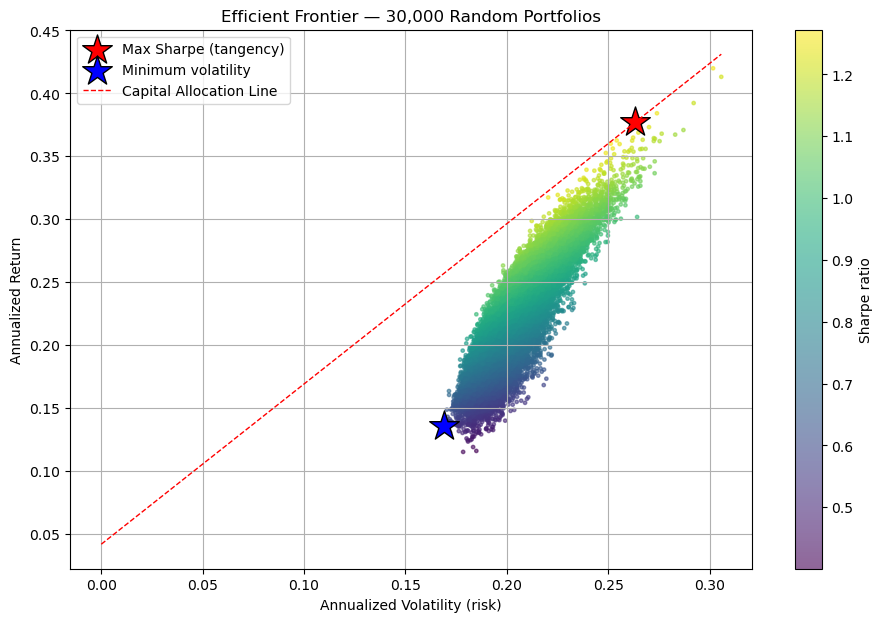

In [12]:
fig, ax = plt.subplots(figsize=(11, 7))

# All random portfolios, colored by Sharpe ratio
sc = ax.scatter(portfolios['Volatility'], portfolios['Return'],
                c=portfolios['Sharpe'], cmap='viridis', s=6, alpha=0.6)
fig.colorbar(sc, label='Sharpe ratio')

# Mark the max-Sharpe portfolio (red star)
ax.scatter(portfolios.loc[max_sharpe_idx, 'Volatility'],
           portfolios.loc[max_sharpe_idx, 'Return'],
           marker='*', color='red', s=500, edgecolors='black',
           label='Max Sharpe (tangency)')

# Mark the minimum-volatility portfolio (blue star)
ax.scatter(portfolios.loc[min_vol_idx, 'Volatility'],
           portfolios.loc[min_vol_idx, 'Return'],
           marker='*', color='blue', s=500, edgecolors='black',
           label='Minimum volatility')

# Draw the Capital Allocation Line from Rf through the tangency portfolio
tan_v = portfolios.loc[max_sharpe_idx, 'Volatility']
tan_r = portfolios.loc[max_sharpe_idx, 'Return']
x_line = np.linspace(0, portfolios['Volatility'].max(), 50)
ax.plot(x_line, Rf + (tan_r - Rf) / tan_v * x_line,
        'r--', linewidth=1, label='Capital Allocation Line')

ax.set_xlabel('Annualized Volatility (risk)')
ax.set_ylabel('Annualized Return')
ax.set_title('Efficient Frontier — 30,000 Random Portfolios')
ax.legend()
plt.show()

## Step 8 — Conclusion & the story for our presentation

**How we chose our 10 stocks.** We started with a spread across sectors (tech, financials, healthcare, energy, staples, retail, utilities) on purpose. Our performance analysis showed the tech names delivered the highest returns but also the highest volatility, while staples and the utility were steadier but lower-returning. The correlation heatmap confirmed our hypothesis: the tech block moves together, while staples, the utility, and energy are much less correlated with tech — those are the names that provide real diversification.

**What the optimizer did with that.** The max-Sharpe portfolio leans toward the names that offered the best return *per unit of risk*, but it doesn't put everything in one stock — it blends in the lower-correlation names to hold total volatility down. That trade-off is exactly what Modern Portfolio Theory is designed to find.

**The efficient frontier** shows the whole menu of risk/return trade-offs. Our red star sits at the point where the Sharpe ratio (return earned per unit of risk above the risk-free rate) is highest — the best "bang for your buck" portfolio available from these 10 stocks.

**Caveats (good to mention):** these expected returns are just historical averages over one 5-year window, so they are not a prediction of the future. Different windows or a different risk-free rate would shift the optimal weights. The Monte Carlo method also only approximates the true optimum, though 30,000 samples gets us very close.

---
### Quick reference — what to say in ~5 minutes
1. *Our 10 picks and why* (sector diversification) → show the table.
2. *Performance analysis* → per-stock return/vol bars + growth-of-\$1 plot.
3. *Correlation heatmap* → point out the tech block vs. the low-correlation names.
4. *Run the optimizer* → show the max-Sharpe weights bar chart.
5. *Efficient frontier* → point to the red star and explain the risk/return trade-off.